# Total usage days vs Sleep Usage Days

In [50]:
import pandas as pd

In [ ]:
df_daily_activity = pd.read_csv('usage-files-download/df_daily_activity.csv')
df_sleep = pd.read_csv('usage-files-download/df_sleep.csv')


In [52]:
df_daily_activity

,user_id,activity_date,total_steps,total_distance,tracker_distance,logged_activities_distance,very_active_distance,moderately_active_distance,light_active_distance,sedentary_active_distance,very_active_minutes,fairly_active_minutes,lightly_active_minutes,sedentary_minutes,calories,activity_month,date
0,1503960366,2016-03-25,11004,7.110000,7.110000,0.0,2.57,0.46,4.07,0.00,33,12,205,804,1819,March,2016-03-25
1,1503960366,2016-03-26,17609,11.550000,11.550000,0.0,6.92,0.73,3.91,0.00,89,17,274,588,2154,March,2016-03-26
2,1503960366,2016-03-27,12736,8.530000,8.530000,0.0,4.66,0.16,3.71,0.00,56,5,268,605,1944,March,2016-03-27
3,1503960366,2016-03-28,13231,8.930000,8.930000,0.0,3.19,0.79,4.95,0.00,39,20,224,1080,1932,March,2016-03-28
4,1503960366,2016-03-29,12041,7.850000,7.850000,0.0,2.16,1.09,4.61,0.00,28,28,243,763,1886,March,2016-03-29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
452,8877689391,2016-04-08,23014,20.389999,20.389999,0.0,11.10,0.63,8.62,0.00,70,29,359,982,4196,April,2016-04-08
453,8877689391,2016-04-09,16470,8.070000,8.070000,0.0,0.00,0.02,8.02,0.00,90,9,289,1052,3841,April,2016-04-09
454,8877689391,2016-04-10,28497,27.530001,27.530001,0.0,21.92,1.12,4.46,0.00,128,46,211,1055,4526,April,2016-04-10
455,8877689391,2016-04-11,10622,8.060000,8.060000,0.0,1.47,0.15,6.37,0.01,18,7,225,1190,2820,April,2016-04-11


In [53]:
df_activity_days = df_daily_activity[
    df_daily_activity['total_steps']>0][['user_id','date']].drop_duplicates()
df_activity_days

,user_id,date
0,1503960366,2016-03-25
1,1503960366,2016-03-26
2,1503960366,2016-03-27
3,1503960366,2016-03-28
4,1503960366,2016-03-29
...,...,...
452,8877689391,2016-04-08
453,8877689391,2016-04-09
454,8877689391,2016-04-10
455,8877689391,2016-04-11


In [54]:
df_activity_days['activity_recorded'] = 1
df_activity_days

,user_id,date,activity_recorded
0,1503960366,2016-03-25,1
1,1503960366,2016-03-26,1
2,1503960366,2016-03-27,1
3,1503960366,2016-03-28,1
4,1503960366,2016-03-29,1
...,...,...,...
452,8877689391,2016-04-08,1
453,8877689391,2016-04-09,1
454,8877689391,2016-04-10,1
455,8877689391,2016-04-11,1


## Siapkan tanggal penggunaan fitur Sleep

In [55]:
df_sleep_days = df_sleep[['user_id','date']].drop_duplicates()

In [56]:
# Tambahkan penanda penggunaan fitur Sleep:
df_sleep_days['sleep_recorded'] = 1

In [57]:
# Gabungkan berdasarkan user_id dan date
df_activity_and_sleep = pd.merge(
    df_activity_days,
    df_sleep_days,
    on=['user_id','date'],
    how='left'
)

In [58]:
# Replace NaN values with 0:
df_activity_and_sleep['sleep_recorded'] = (
    df_activity_and_sleep['sleep_recorded']
    .fillna(0)
    .astype(int)
)

In [59]:
df_missing_sleep = df_activity_and_sleep[
    df_activity_and_sleep['sleep_recorded'] == 0
]

df_missing_sleep

,user_id,date,activity_recorded,sleep_recorded
5,1503960366,2016-03-30,1,0
12,1503960366,2016-04-06,1,0
13,1503960366,2016-04-07,1,0
14,1503960366,2016-04-08,1,0
18,1503960366,2016-04-12,1,0
...,...,...,...,...
391,8877689391,2016-04-08,1,0
392,8877689391,2016-04-09,1,0
393,8877689391,2016-04-10,1,0
394,8877689391,2016-04-11,1,0


In [60]:
df_sleep_summary = (
    df_activity_and_sleep.groupby(
        'user_id',
        as_index=False
    )
    .agg(
        total_activity_days=(
            'activity_recorded',
            'sum'
        ),
        total_sleep_days=(
            'sleep_recorded',
            'sum'
        )
    )
)

df_sleep_summary.head(10)

,user_id,total_activity_days,total_sleep_days
0,1503960366,19,14
1,1624580081,19,0
2,1644430081,10,0
3,1844505072,9,3
4,1927972279,12,10
5,2022484408,12,0
6,2026352035,12,12
7,2320127002,8,0
8,2347167796,14,14
9,2873212765,11,0


In [61]:
df_sleep_summary['missing_sleep_days'] = (
    df_sleep_summary['total_activity_days'] - df_sleep_summary['total_sleep_days']
)
df_sleep_summary.head(10)

,user_id,total_activity_days,total_sleep_days,missing_sleep_days
0,1503960366,19,14,5
1,1624580081,19,0,19
2,1644430081,10,0,10
3,1844505072,9,3,6
4,1927972279,12,10,2
5,2022484408,12,0,12
6,2026352035,12,12,0
7,2320127002,8,0,8
8,2347167796,14,14,0
9,2873212765,11,0,11


## Data Visualization

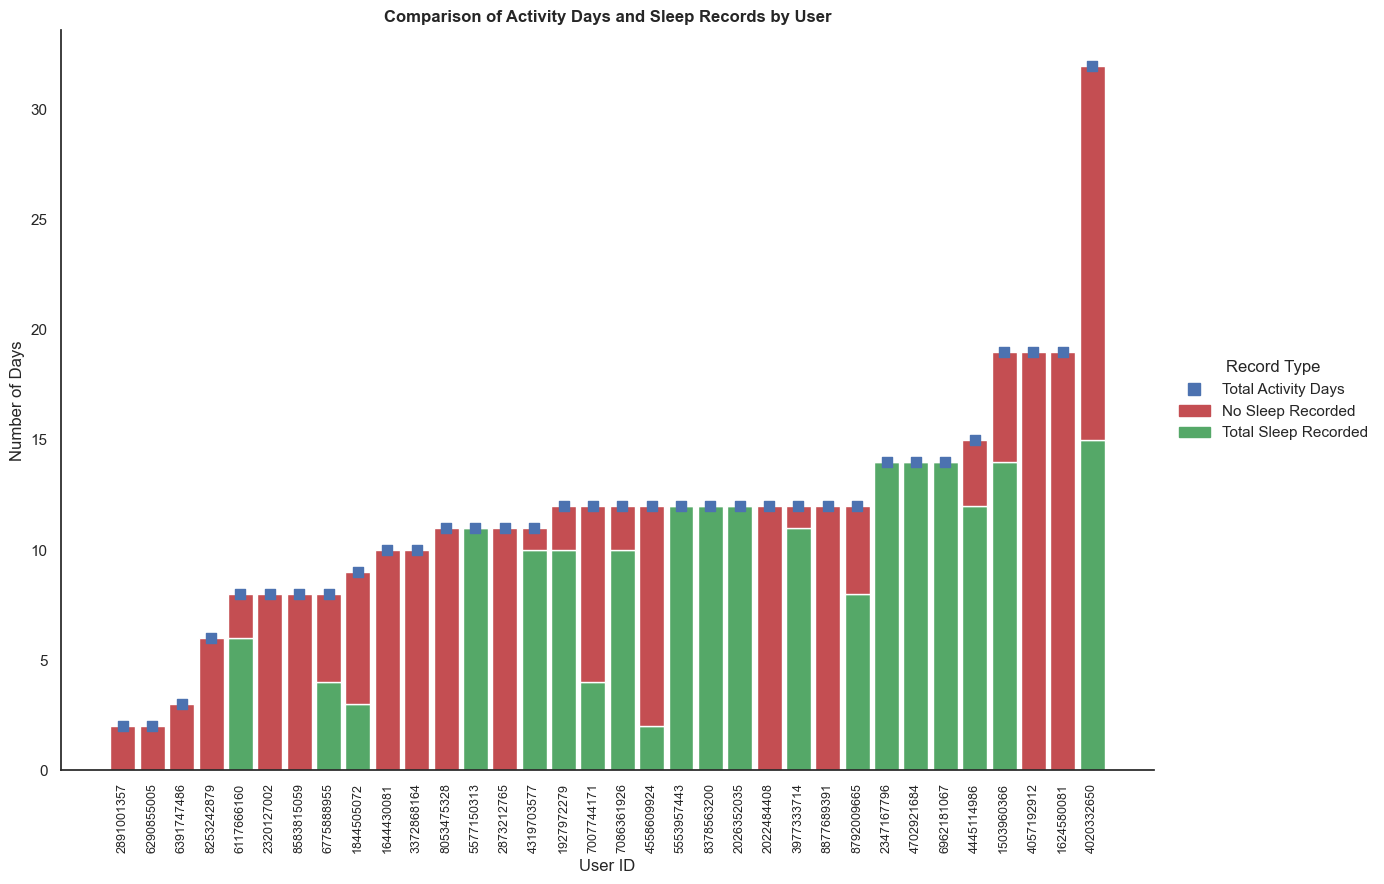

In [62]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import numpy as np

# Sort users by total activity days
df_sleep_chart = (
    df_sleep_summary
    .sort_values('total_activity_days', ascending=True)
    .copy()
)

# Convert user IDs to text
df_sleep_chart['user_id'] = (
    df_sleep_chart['user_id'].astype(str)
)

# Set user positions on the X-axis
x = np.arange(len(df_sleep_chart))

# Use a clean white background
sns.set_theme(style='white')

fig, ax = plt.subplots(figsize=(14, 9))

fig.patch.set_facecolor('white')
ax.set_facecolor('white')

# Green: total sleep-recorded days
ax.bar(
    x,
    df_sleep_chart['total_sleep_days'],
    color='#55A868',
    width=0.85
)

# Red: days with no sleep records
ax.bar(
    x,
    df_sleep_chart['missing_sleep_days'],
    bottom=df_sleep_chart['total_sleep_days'],
    color='#C44E52',
    width=0.85
)

# Blue: total activity-day markers
ax.scatter(
    x,
    df_sleep_chart['total_activity_days'],
    color='#4C72B0',
    marker='s',
    s=55,
    zorder=3
)

# Display user IDs on the X-axis
ax.set_xticks(x)

ax.set_xticklabels(
    df_sleep_chart['user_id'],
    rotation=90,
    fontsize=9
)

ax.set_title(
    'Comparison of Activity Days and Sleep Records by User',
    fontweight='bold'
)

ax.set_xlabel('User ID')
ax.set_ylabel('Number of Days')

# Remove the grid
ax.grid(False)

# Remove the top and right borders
sns.despine(ax=ax)

# Create custom legend items
legend_items = [
    Line2D(
        [0], [0],
        marker='s',
        color='none',
        markerfacecolor='#4C72B0',
        markeredgecolor='#4C72B0',
        markersize=9,
        label='Total Activity Days'
    ),
    Patch(
        color='#C44E52',
        label='No Sleep Recorded'
    ),
    Patch(
        color='#55A868',
        label='Total Sleep Recorded'
    )
]

# Place the legend on the right
ax.legend(
    handles=legend_items,
    title='Record Type',
    loc='center left',
    bbox_to_anchor=(1.01, 0.5),
    frameon=False
)

plt.tight_layout()

plt.savefig(
    'comparison.png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

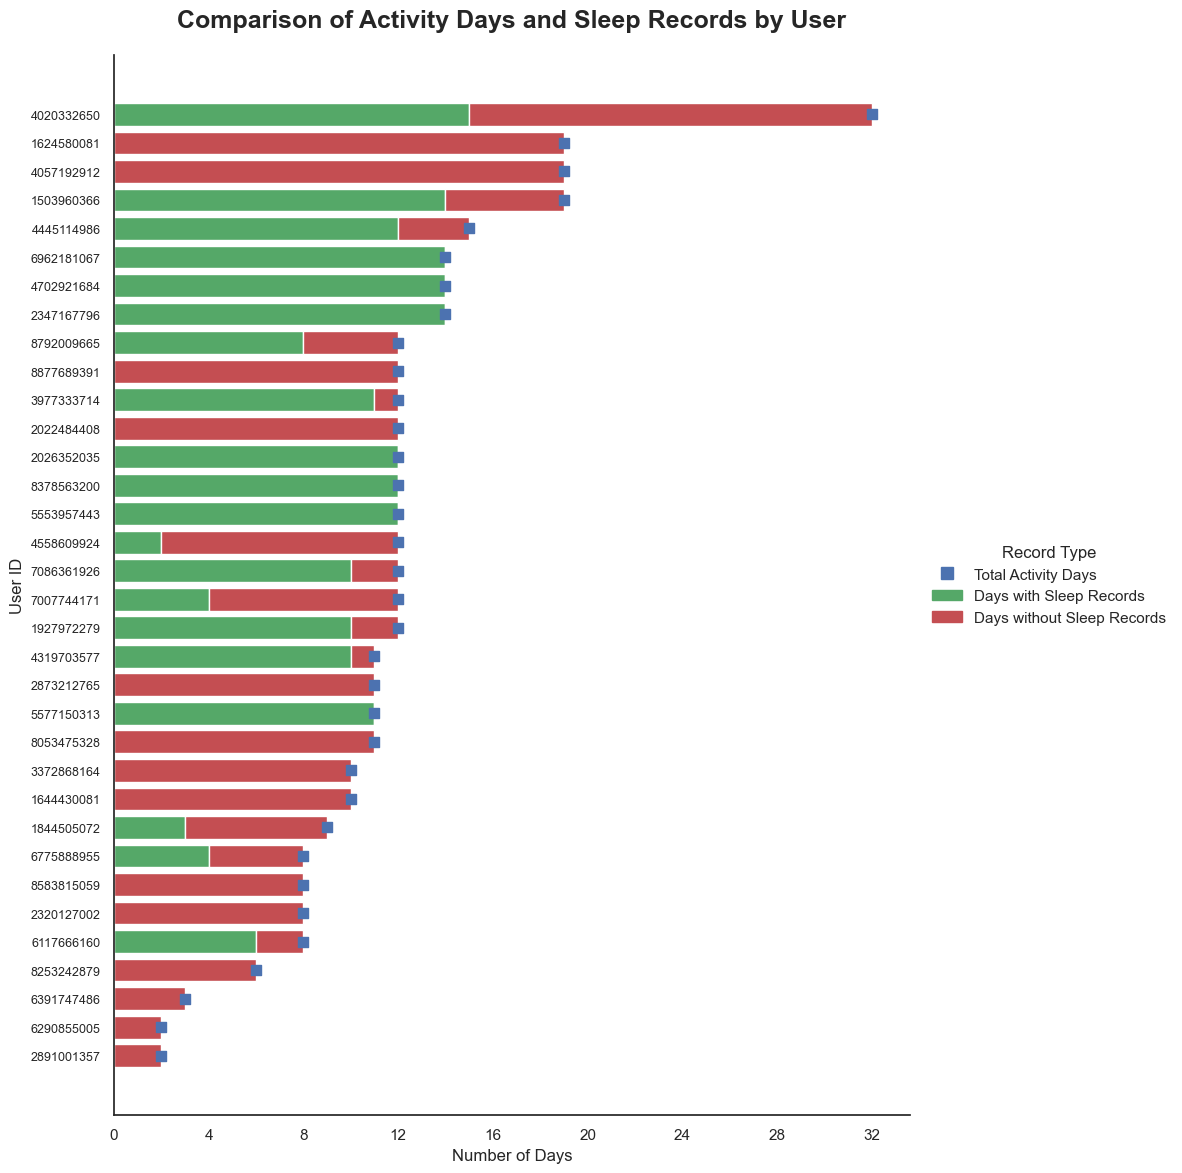

In [66]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
import numpy as np

# Sort users by total activity days
df_sleep_chart = (
    df_sleep_summary
    .sort_values('total_activity_days', ascending=True)
    .copy()
)

# Convert user IDs to text
df_sleep_chart['user_id'] = (
    df_sleep_chart['user_id'].astype(str)
)

# Set user positions on the Y-axis
y = np.arange(len(df_sleep_chart))

# Use a clean white background
sns.set_theme(style='white')

fig, ax = plt.subplots(
    figsize=(12, max(8, len(df_sleep_chart) * 0.35))
)

fig.patch.set_facecolor('white')
ax.set_facecolor('white')

# Green: days with sleep records
ax.barh(
    y,
    df_sleep_chart['total_sleep_days'],
    height=0.8,
    color='#55A868'
)

# Red: days without sleep records, stacked after green
ax.barh(
    y,
    df_sleep_chart['missing_sleep_days'],
    left=df_sleep_chart['total_sleep_days'],
    height=0.8,
    color='#C44E52'
)

# Blue: total activity-day markers
ax.scatter(
    df_sleep_chart['total_activity_days'],
    y,
    color='#4C72B0',
    marker='s',
    s=55,
    zorder=3
)

# Display user IDs on the Y-axis
ax.set_yticks(y)
ax.set_yticklabels(
    df_sleep_chart['user_id'],
    fontsize=9
)

ax.set_title(
    'Comparison of Activity Days and Sleep Records by User',
    fontsize=18,
    fontweight='bold',
    loc='center',
    pad=20
)

ax.set_xlabel('Number of Days')
ax.set_ylabel('User ID')

# Display whole numbers on the X-axis
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlim(left=0)

# Remove the grid
ax.grid(False)

# Remove the top and right borders
sns.despine(ax=ax)

# Create custom legend items
legend_items = [
    Line2D(
        [0], [0],
        marker='s',
        linestyle='None',
        color='#4C72B0',
        markersize=9,
        label='Total Activity Days'
    ),
    Patch(
        color='#55A868',
        label='Days with Sleep Records'
    ),
    Patch(
        color='#C44E52',
        label='Days without Sleep Records'
    )
]

# Place the legend on the right
ax.legend(
    handles=legend_items,
    title='Record Type',
    loc='center left',
    bbox_to_anchor=(1.01, 0.5),
    frameon=False
)

plt.tight_layout()

# Save the chart
plt.savefig(
    'comparison_stacked_bar_chart.png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()